# 10 · HMM + Viterbi route reconstruction (student-test)
Hidden states: the K=8 candidate arcs of each GPS point (with projection position on the arc).
Emission: log of the classifier probability normalised over the point's candidates.
Transition: exp(-|road distance − straight-line distance| / β), road distance from Dijkstra on the directed network;
β grows with √Δt for irregular sampling. Gaps > gap_break seconds or no reachable transition restart the chain.

In [1]:
import sys, os, json, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pathsnap").is_dir()), None)
if _root is None:
    raise RuntimeError("src/pathsnap not found: unzip all zips of the set into the same pathsnap/ folder")
sys.path.insert(0, str(_root / "src")); os.chdir(_root / "notebooks")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from pathsnap import io, labels, hmm, pipeline
from pathsnap.evaluate import continuity, route_f1

model = joblib.load("../artifacts/models/M6_lightgbm_tuned.joblib")
trips = {}
for tid in io.list_trips("student_test"):
    tr = io.load_trip("student_test", tid)
    lab, _ = labels.align_route(tr)
    C, D, T, P = pipeline.candidate_probs(tr, model)
    trips[tid] = (tr, lab, C, D, T, P)

In [2]:
def run(params, mode="classifier", sigma=7.0):
    rows = []
    for tid, (tr, lab, C, D, T, P) in trips.items():
        t0 = time.time()
        dec, breaks = hmm.viterbi(tr, C, T, pipeline.emissions(P, D, mode, sigma), params)
        rows.append(dict(trip=tid, **pipeline.score(tr, dec, lab), breaks=breaks, seconds=time.time() - t0))
    return pd.DataFrame(rows)

grid = []
for beta in [1, 2, 5, 10, 20]:
    for w in [0.25, 0.5, 1.0, 2.0]:
        r = run(dict(beta=beta, emis_weight=w))
        grid.append(dict(beta=beta, emis_weight=w, **r.drop(columns="trip").mean().to_dict()))
grid = pd.DataFrame(grid)
grid.to_csv("../outputs/hmm_grid.csv", index=False)
grid.pivot(index="beta", columns="emis_weight", values="top1_acc").round(4)

emis_weight,0.25,0.50,1.00,2.00
beta,,,,
1,0.9381,0.9438,0.9492,0.9442
2,0.9438,0.9492,0.9442,0.9393
5,0.9522,0.9422,0.9387,0.9315
10,0.9422,0.9387,0.9315,0.9264
20,0.9387,0.9315,0.9264,0.9248


In [3]:
best = grid.sort_values(["top1_acc", "route_continuity"], ascending=False).iloc[0]
params = dict(hmm.DEFAULTS, beta=float(best.beta), emis_weight=float(best.emis_weight))
print("decoder params:", params)

clf_rows = []
for tid, (tr, lab, C, D, T, P) in trips.items():
    seq = np.where((C >= 0).any(1), C[np.arange(len(C)), np.argmax(np.where(C >= 0, P, -1), 1)], -1)
    clf_rows.append(dict(trip=tid, **pipeline.score(tr, seq, lab)))
nearest_rows = [dict(trip=tid, **pipeline.score(tr, C[:, 0], lab)) for tid, (tr, lab, C, D, T, P) in trips.items()]
methods = {
    "nearest arc": pd.DataFrame(nearest_rows),
    "classifier only": pd.DataFrame(clf_rows),
    "HMM (distance emission)": run(params, "distance"),
    "classifier + HMM": run(params),
}
summary = pd.DataFrame({k: v[["top1_acc", "route_continuity", "route_f1"]].mean() for k, v in methods.items()}).T
summary.to_csv("../outputs/hmm_comparison.csv")
summary.round(4)

decoder params: {'beta': 5.0, 'emis_weight': 0.25, 'limit': 2000.0, 'gap_break': 120.0}


,top1_acc,route_continuity,route_f1
nearest arc,0.5750,0.4665,0.5904
classifier only,0.9001,0.7540,0.8867
HMM (distance emission),0.9323,0.9004,0.9263
classifier + HMM,0.9522,0.9064,0.9340


,nearest arc,classifier only,HMM (distance emission),classifier + HMM,gain
trip,,,,,
00000000,0.5665,0.9521,0.9784,0.9840,0.0320
00000007,0.5576,0.9040,0.9978,0.9993,0.0953
00000009,0.4109,0.8751,0.8389,0.9037,0.0286
00000040,0.5813,0.9539,0.9750,0.9793,0.0254
00000052,0.8244,0.9809,0.9847,1.0000,0.0191
00000056,0.6930,0.9058,0.9336,0.9550,0.0493
00000065,0.6914,0.8529,0.8568,0.8685,0.0156
00000076,0.4031,0.9246,0.9192,0.9717,0.0471
00000077,0.4191,0.7625,0.9097,0.9059,0.1434


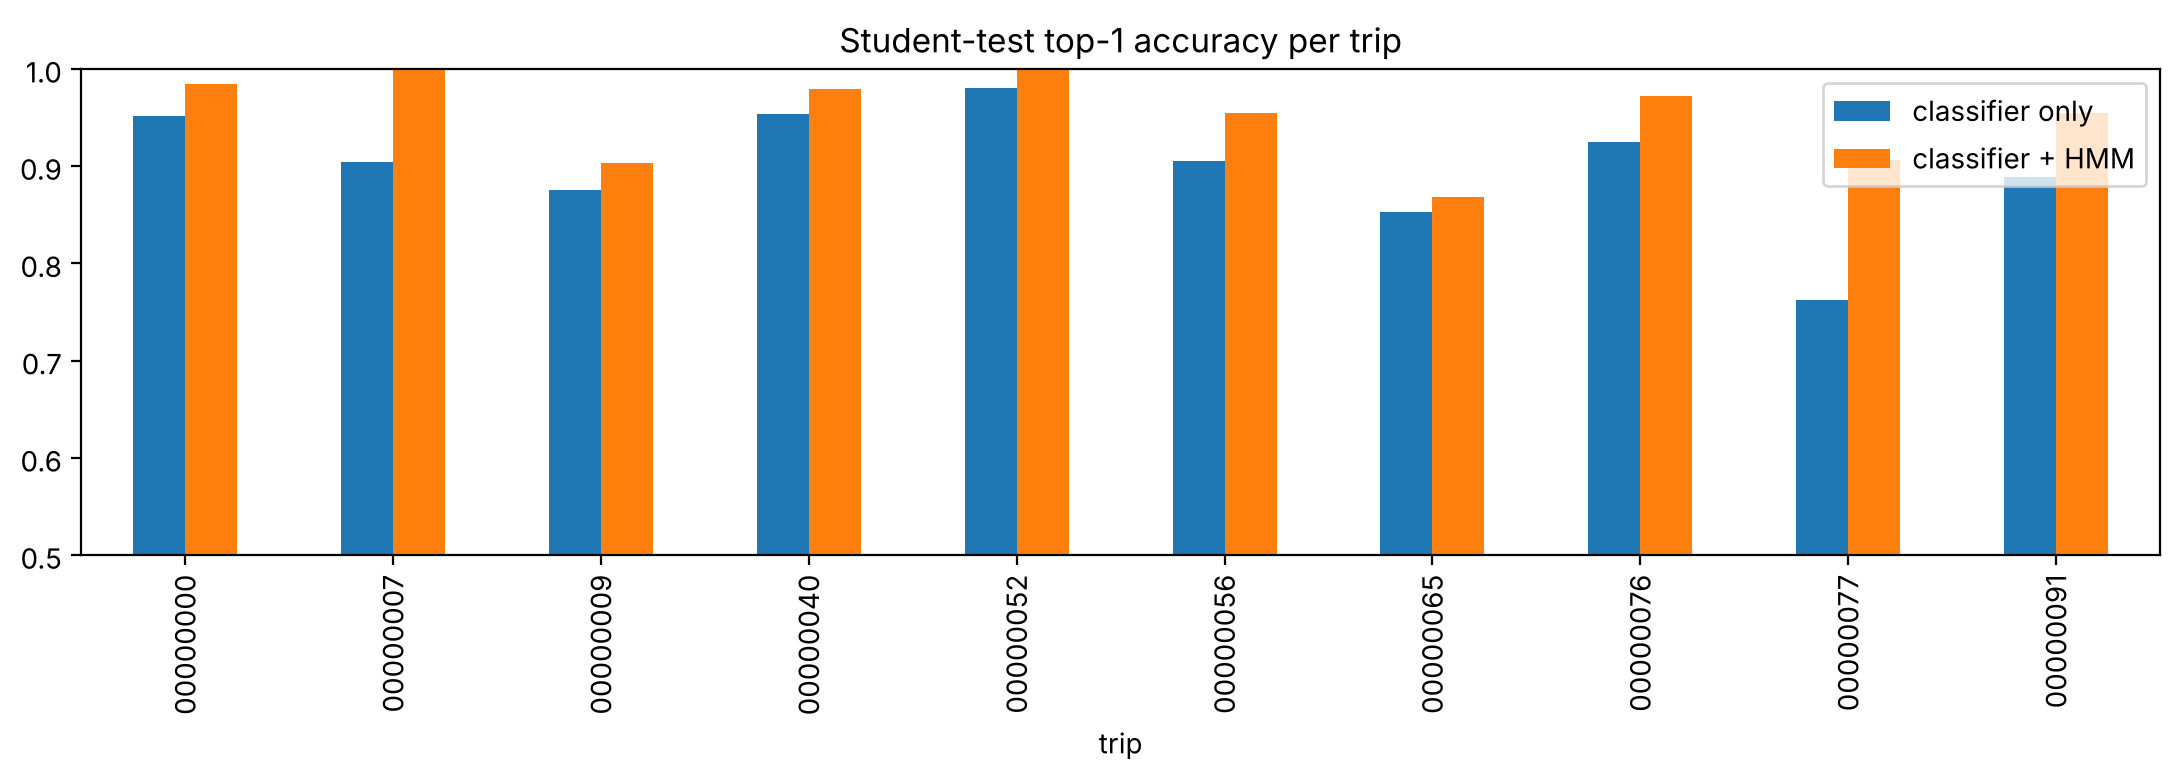

In [4]:
per_trip = pd.DataFrame({k: v.set_index("trip").top1_acc for k, v in methods.items()})
per_trip.to_csv("../outputs/hmm_per_trip.csv")
ax = per_trip[["classifier only", "classifier + HMM"]].plot.bar(figsize=(11, 4), ylim=(.5, 1), title="Student-test top-1 accuracy per trip")
plt.tight_layout(); plt.savefig("../outputs/figures/hmm_per_trip.png", dpi=120)
per_trip.assign(gain=per_trip["classifier + HMM"] - per_trip["classifier only"]).round(4)

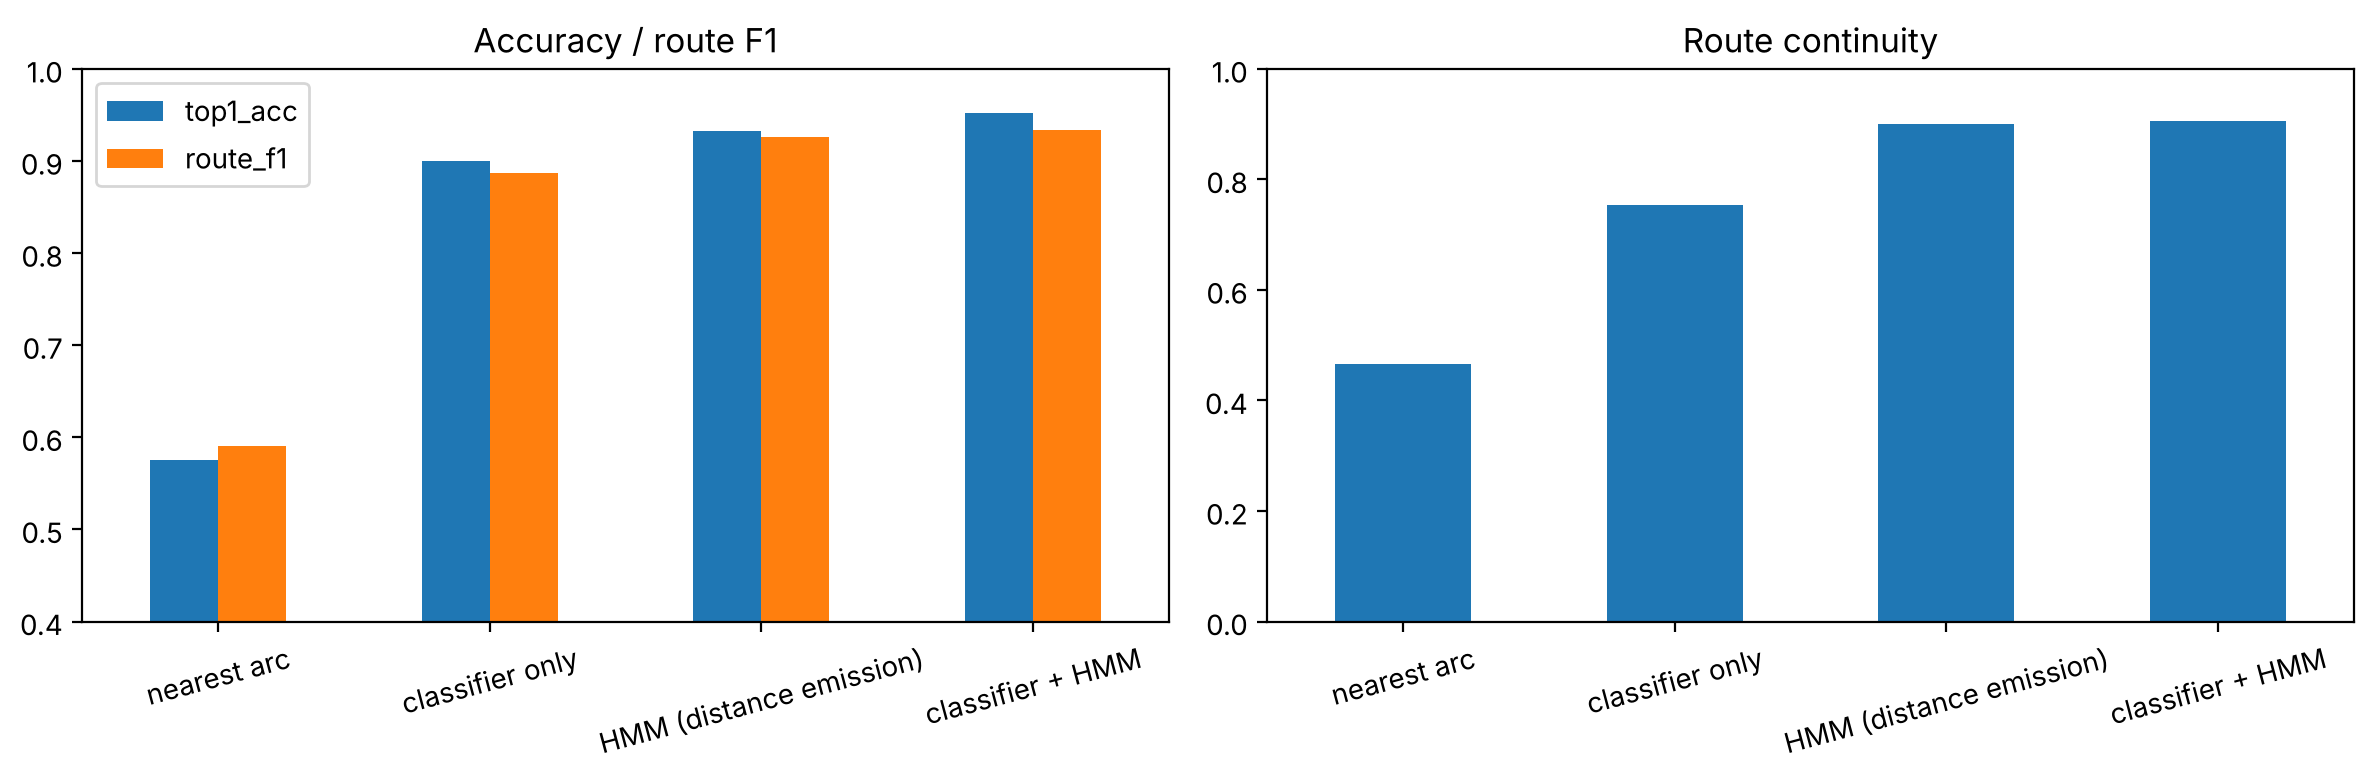

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
summary[["top1_acc", "route_f1"]].plot.bar(ax=ax[0], ylim=(.4, 1), rot=15, title="Accuracy / route F1")
summary[["route_continuity"]].plot.bar(ax=ax[1], ylim=(0, 1), rot=15, title="Route continuity", legend=False)
plt.tight_layout(); plt.savefig("../outputs/figures/hmm_vs_classifier.png", dpi=120)

In [6]:
cfg = dict(model_file="models/M6_lightgbm_tuned.joblib", K=8, radius=100.0, features=pipeline.FEATURES, hmm=params)
json.dump(cfg, open("../artifacts/config.json", "w"), indent=2)
cfg

{'model_file': 'models/M6_lightgbm_tuned.joblib',
 'K': 8,
 'radius': 100.0,
 'features': ['dist',
  'rank',
  'dist_gap',
  'dist_ratio',
  'head_diff',
  'move',
  'speed',
  'dt',
  'frac',
  'alen',
  'n_cand',
  'n_cand30',
  'ctx_prev',
  'ctx_next',
  'ctx_mean',
  'out_deg',
  'in_deg',
  'has_rev'],
 'hmm': {'beta': 5.0,
  'emis_weight': 0.25,
  'limit': 2000.0,
  'gap_break': 120.0}}